In [2]:
print("hello")

hello


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
print(pd.__version__, sklearn.__version__)

2.2.3 1.6.1


In [7]:
import pandas as pd
cols = ["mpg","cylinders","displacement","horsepower","weight","acceleration","model_year","origin","name"]
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
df = pd.read_csv(url, names=cols, na_values="?", sep=r"\s+")
df = df.drop(columns="name")
print(df.shape)
print(df.isna().sum())

(398, 8)
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64


In [8]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
0,18.0,8,307.0,130.0,3504.0,12.0,70,1
1,15.0,8,350.0,165.0,3693.0,11.5,70,1
2,18.0,8,318.0,150.0,3436.0,11.0,70,1
3,16.0,8,304.0,150.0,3433.0,12.0,70,1
4,17.0,8,302.0,140.0,3449.0,10.5,70,1


In [9]:
df.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


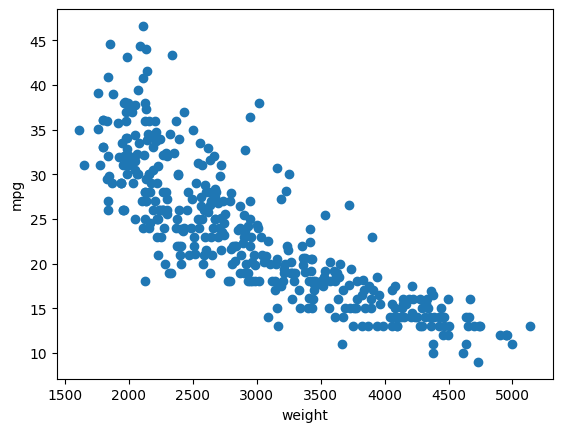

In [11]:
plt.scatter(df["weight"], df["mpg"])
plt.xlabel("weight")
plt.ylabel("mpg")
plt.show()

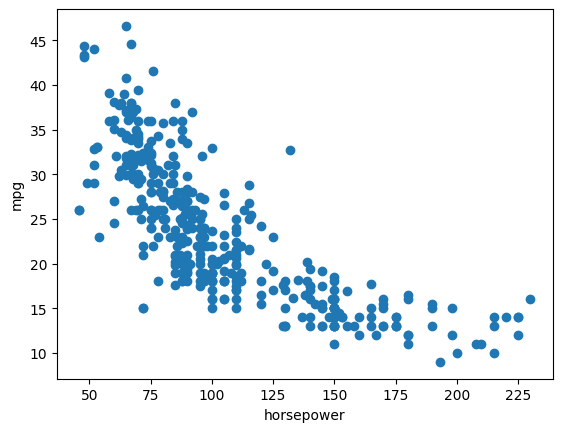

In [12]:
plt.scatter(df["horsepower"], df["mpg"])
plt.xlabel("horsepower")
plt.ylabel("mpg")
plt.show()

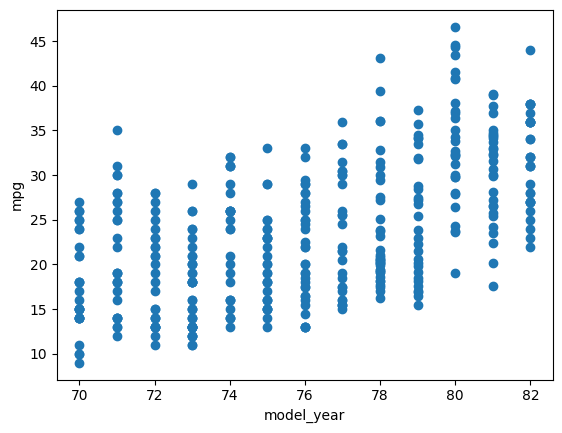

In [14]:
plt.scatter(df["model_year"], df["mpg"])
plt.xlabel("model_year")
plt.ylabel("mpg")
plt.show()


In [15]:
df.corr()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
mpg,1.000000,-0.775396,-0.804203,-0.778427,-0.831741,0.420289,0.579267,0.563450
cylinders,-0.775396,1.000000,0.950721,0.842983,0.896017,-0.505419,-0.348746,-0.562543
displacement,-0.804203,0.950721,1.000000,0.897257,0.932824,-0.543684,-0.370164,-0.609409
horsepower,-0.778427,0.842983,0.897257,1.000000,0.864538,-0.689196,-0.416361,-0.455171
weight,-0.831741,0.896017,0.932824,0.864538,1.000000,-0.417457,-0.306564,-0.581024
acceleration,0.420289,-0.505419,-0.543684,-0.689196,-0.417457,1.000000,0.288137,0.205873
model_year,0.579267,-0.348746,-0.370164,-0.416361,-0.306564,0.288137,1.000000,0.180662
origin,0.563450,-0.562543,-0.609409,-0.455171,-0.581024,0.205873,0.180662,1.000000


In [16]:
from sklearn.model_selection import train_test_split
X = df.drop(columns="mpg")
y = df["mpg"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(318, 7) (80, 7)


In [17]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
base = DummyRegressor(strategy="mean").fit(X_train, y_train)
print("train mean:", y_train.mean())
print("baseline test MAE:", mean_absolute_error(y_test, base.predict(X_test)))

train mean: 23.60817610062893
baseline test MAE: 5.955408805031446


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression

num_cols = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
cat_cols = ["origin"]

num_pipe = Pipeline([
("impute", SimpleImputer(strategy="median")),
("scale", StandardScaler()),
])

preprocess = ColumnTransformer([
("num", num_pipe, num_cols),
("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

lin = Pipeline([
("prep", preprocess),
("model", LinearRegression()),
])

lin.fit(X_train, y_train)
print("linear train MAE:", mean_absolute_error(y_train, lin.predict(X_train)))

linear train MAE: 2.604628219614551


In [19]:
df.to_csv("auto_mpg.csv", index=False)